# 02 · Baseline: reading real architectural CAD drawings

**Data:** 5,308 real CAD floor-plan tiles (≈20 m × 20 m crops, coloured line work on black) from 1,116 buildings: images from [`Voxel51/FloorPlanCAD`](https://huggingface.co/datasets/Voxel51/FloorPlanCAD), gold labels from the original [FloorPlanCAD](https://floorplancad.github.io/) SVG annotations (the Voxel51 class names are scrambled; see `01_official_labels.ipynb`). 9 classes: doors, windows, toilets, sinks, staircases, elevators, urinals, stoves, bathtubs.

**Benchmark** (split by building, so no building is in both):

| Split | Questions | Buildings | Mix |
|---|---|---|---|
| train | 6,219 | ≈930 | for SFT |
| **test** | **1,000** | **185** | 495 counting ("How many windows…?", answers 1–12) + 505 presence ("Does it contain any elevators?", 49% yes) |

Score: exact match (also reported: counting within ±1).

In [1]:
import asyncio, json, os, sys
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "fp_common.py").exists():
    HERE = Path("experiments/floorplancad-symbol-counting").resolve()
os.chdir(HERE)
sys.path.insert(0, str(HERE))

import fp_common as f
import fp_report as rep
rep.fv.apply_theme()
print(f.build(), "· API key set:", bool(os.getenv("FIREWORKS_API_KEY")))

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 6219, 'test': 1000} · API key set: True


Does this floor plan contain any urinals? → no


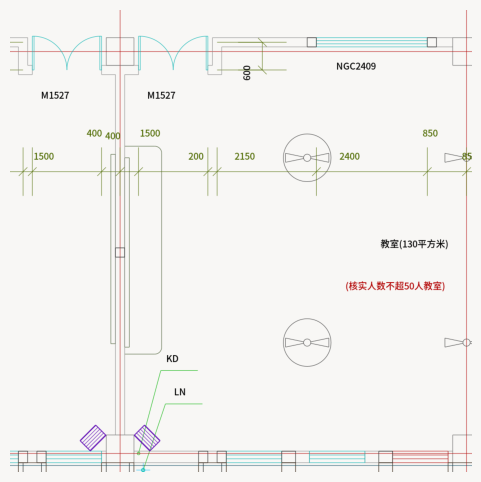

In [2]:
r = f.load_split("test")[0]
from PIL import Image
print(r["question"], "→", r["answer"])
rep.fv.plt.figure(figsize=(6, 6)); rep.fv.plt.imshow(Image.open(f.image_path(r))); rep.fv.plt.axis("off"); rep.fv.plt.show()

## Open models (Fireworks) · GLM ≈$0.30, Muse ≈$3, Kimi ≈$10

In [3]:
for m in ("glm", "muse", "kimi"):
    await f.eval_model(m, m)

glm: GLM 5.3 Flash on test · n=1 · to_run=0


images: 0it [00:00, ?it/s]

images: 0it [00:00, ?it/s]

glm: accuracy 65.4% · counting exact 46.5%, within ±1 74.5% (n=1000)
muse: Muse Spark on test · n=1 · to_run=0


images: 0it [00:00, ?it/s]

images: 0it [00:00, ?it/s]

muse: accuracy 68.9% · counting exact 52.5%, within ±1 79.6% (n=1000)
kimi: Kimi K3 on test · n=1 · to_run=0


images: 0it [00:00, ?it/s]

images: 0it [00:00, ?it/s]

kimi: accuracy 64.5% · counting exact 46.1%, within ±1 75.2% (n=1000)


## Closed models (OpenRouter) · Gemini ≈$5, GPT ≈$4, Opus ≈$12

In [4]:
for m in ("gemini4", "gpt61", "opus55"):
    await f.eval_model(m, m)

gemini4: Gemini 4 Argon on test · n=1 · to_run=0


images: 0it [00:00, ?it/s]

images: 0it [00:00, ?it/s]

gemini4: accuracy 76.8% · counting exact 63.2%, within ±1 85.5% (n=1000)
gpt61: GPT-6.1 Terra Pro on test · n=1 · to_run=0


images: 0it [00:00, ?it/s]

images: 0it [00:00, ?it/s]

gpt61: accuracy 70.5% · counting exact 53.5%, within ±1 79.4% (n=1000)
opus55: Claude Opus 5.5 on test · n=1 · to_run=0


images: 0it [00:00, ?it/s]

images: 0it [00:00, ?it/s]

opus55: accuracy 75.2% · counting exact 61.2%, within ±1 84.6% (n=1000)


## Leaderboard

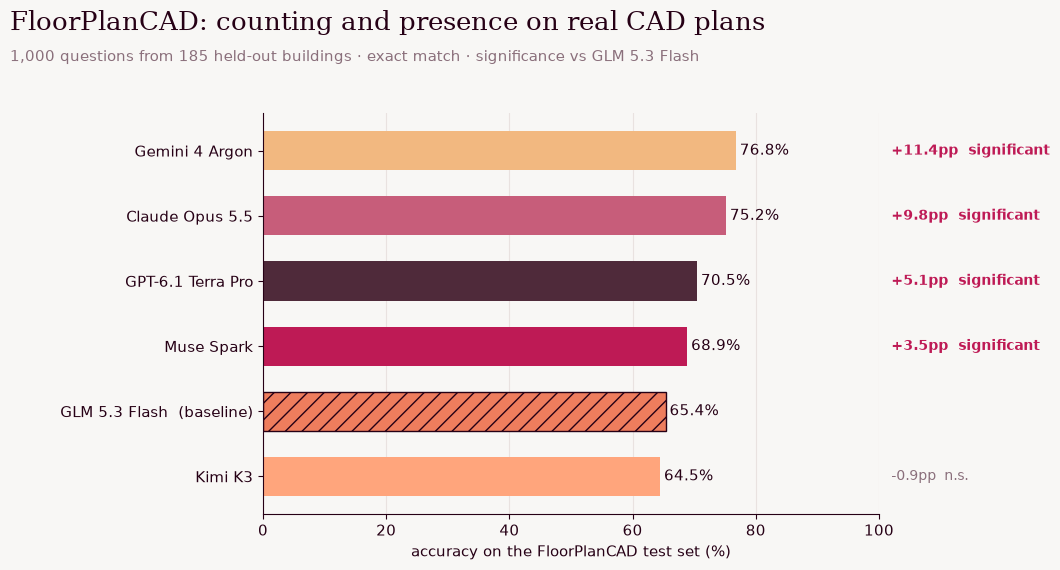

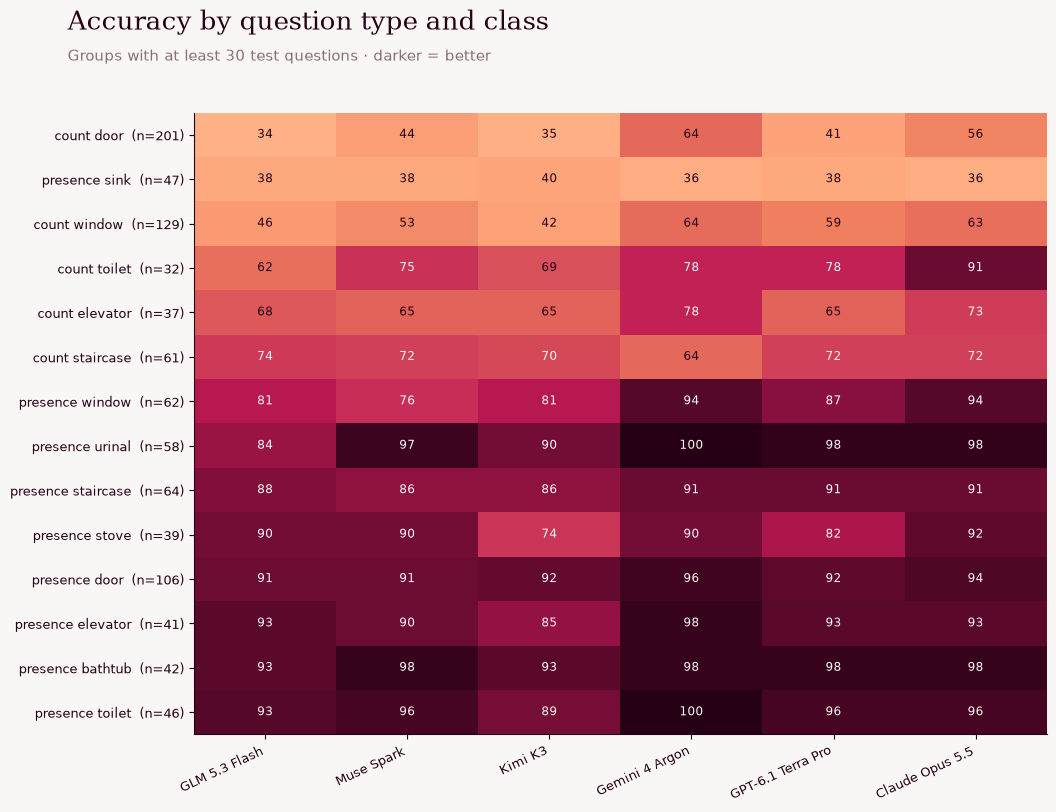

In [5]:
ALL = ["glm", "muse", "kimi", "gemini4", "gpt61", "opus55"]
rep.leaderboard(ALL, "glm", "FloorPlanCAD: counting and presence on real CAD plans",
                "1,000 questions from 185 held-out buildings · exact match · significance vs GLM 5.3 Flash")
rep.class_heatmap(ALL)

In [6]:
rep.cost_table(ALL)
rep.significance_table([(m, "glm") for m in ALL if m != "glm"])

,accuracy,errors,cost $,$ per 1k questions,median latency s
system,,,,,
GLM 5.3 Flash,65.4%,0,0.23,0.23,62.8
Muse Spark,68.9%,0,3.22,3.22,426.4
Kimi K3,64.5%,0,16.29,16.29,770.3
Gemini 4 Argon,76.8%,0,3.48,3.48,442.8
GPT-6.1 Terra Pro,70.5%,0,4.80,4.80,287.8
Claude Opus 5.5,75.2%,0,10.10,10.10,278.2


,n,acc_a,acc_b,Δpp,only_a,only_b,McNemar p,boot 95% CI,significant,notes
pair,,,,,,,,,,
Muse Spark vs GLM 5.3 Flash,1000,68.9%,65.4%,3.5,103,68,0.0091,"[+0.7, +6.2]",True,GAIN holds under both tests
Kimi K3 vs GLM 5.3 Flash,1000,64.5%,65.4%,-0.9,83,92,0.5455,"[-3.9, +2.0]",False,within noise
Gemini 4 Argon vs GLM 5.3 Flash,1000,76.8%,65.4%,11.4,160,46,0.0000,"[+8.4, +14.3]",True,GAIN holds under both tests
GPT-6.1 Terra Pro vs GLM 5.3 Flash,1000,70.5%,65.4%,5.1,116,65,0.0002,"[+2.4, +7.6]",True,GAIN holds under both tests
Claude Opus 5.5 vs GLM 5.3 Flash,1000,75.2%,65.4%,9.8,147,49,0.0000,"[+6.7, +12.8]",True,GAIN holds under both tests


,n,acc_a,acc_b,Δpp,only_a,only_b,McNemar p,boot 95% CI,significant,notes
pair,,,,,,,,,,
Muse Spark vs GLM 5.3 Flash,1000,68.9%,65.4%,3.5,103,68,0.0091,"[+0.7, +6.2]",True,GAIN holds under both tests
Kimi K3 vs GLM 5.3 Flash,1000,64.5%,65.4%,-0.9,83,92,0.5455,"[-3.9, +2.0]",False,within noise
Gemini 4 Argon vs GLM 5.3 Flash,1000,76.8%,65.4%,11.4,160,46,0.0000,"[+8.4, +14.3]",True,GAIN holds under both tests
GPT-6.1 Terra Pro vs GLM 5.3 Flash,1000,70.5%,65.4%,5.1,116,65,0.0002,"[+2.4, +7.6]",True,GAIN holds under both tests
Claude Opus 5.5 vs GLM 5.3 Flash,1000,75.2%,65.4%,9.8,147,49,0.0000,"[+6.7, +12.8]",True,GAIN holds under both tests


**Stats.** McNemar on paired right/wrong per question, plus a bootstrap that resamples whole *buildings* (tiles from one building are correlated). A gain counts only when both are significant.